Generate and analyze AUC-ROC and precision-recall curves to evaluate classification thresholds, comparing model discriminatory power in imbalanced datasets for optimal threshold selection.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 1000

In [4]:
age = np.random.normal(60, 10, n_samples).clip(20, 85)
troponin = np.random.exponential(scale=1.5, size=n_samples).round(3)
creatine_kinase = np.random.exponential(scale=2.0, size=n_samples).round(2)
systolic_bp = np.random.normal(135, 20, n_samples).clip(90, 200).round(1)

In [6]:
risk_logits = (
    0.02 * (age - 60)
    + 0.8 * troponin
    + 0.3 * creatine_kinase
    + 0.03 * (systolic_bp - 135)
    - 4.2  
)

In [7]:
probs = 1 / (1 + np.exp(-risk_logits))
target = (probs > np.random.uniform(0, 1, n_samples)).astype(int)

In [8]:
df_eval = pd.DataFrame({
    'age': age.round(1),
    'troponin_ngml': troponin,
    'creatine_kinase_ul': creatine_kinase,
    'systolic_bp': systolic_bp,
    'cardiac_event': target
})

In [9]:
neg_count, pos_count = np.bincount(df_eval['cardiac_event'])

In [10]:
print("Dataset Shape:", df_eval.shape)
print(f"Class Distribution: Negative={neg_count}, Positive={pos_count} (Ratio: {neg_count/pos_count:.1f}:1)")

Dataset Shape: (1000, 5)
Class Distribution: Negative=872, Positive=128 (Ratio: 6.8:1)


In [11]:
import xgboost as xgb
from sklearn.model_selection import train_test_split

In [12]:
X = df_eval.drop(columns=['cardiac_event'])
y = df_eval['cardiac_event']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

In [14]:
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

In [15]:
eval_xgb = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=4,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42
)

In [16]:
eval_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [17]:
y_proba = eval_xgb.predict_proba(X_test)[:, 1]

In [18]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

In [19]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

In [20]:
youden_j = tpr - fpr
best_youden_idx = np.argmax(youden_j)
best_youden_thresh = roc_thresholds[best_youden_idx]

In [21]:
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

In [22]:
f1_scores = (2 * precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-10)
best_f1_idx = np.argmax(f1_scores)
best_f1_thresh = pr_thresholds[best_f1_idx]

In [23]:
print(f"ROC-AUC Score            : {roc_auc:.4f}")
print(f"PR-AUC Score             : {pr_auc:.4f}")
print(f"Optimal Threshold (Youden's J) : {best_youden_thresh:.4f} (Max J = {youden_j[best_youden_idx]:.4f})")
print(f"Optimal Threshold (Max F1-Score): {best_f1_thresh:.4f} (Max F1 = {f1_scores[best_f1_idx]:.4f})")

ROC-AUC Score            : 0.8090
PR-AUC Score             : 0.4888
Optimal Threshold (Youden's J) : 0.1679 (Max J = 0.4906)
Optimal Threshold (Max F1-Score): 0.6195 (Max F1 = 0.5070)


In [24]:
import matplotlib.pyplot as plt

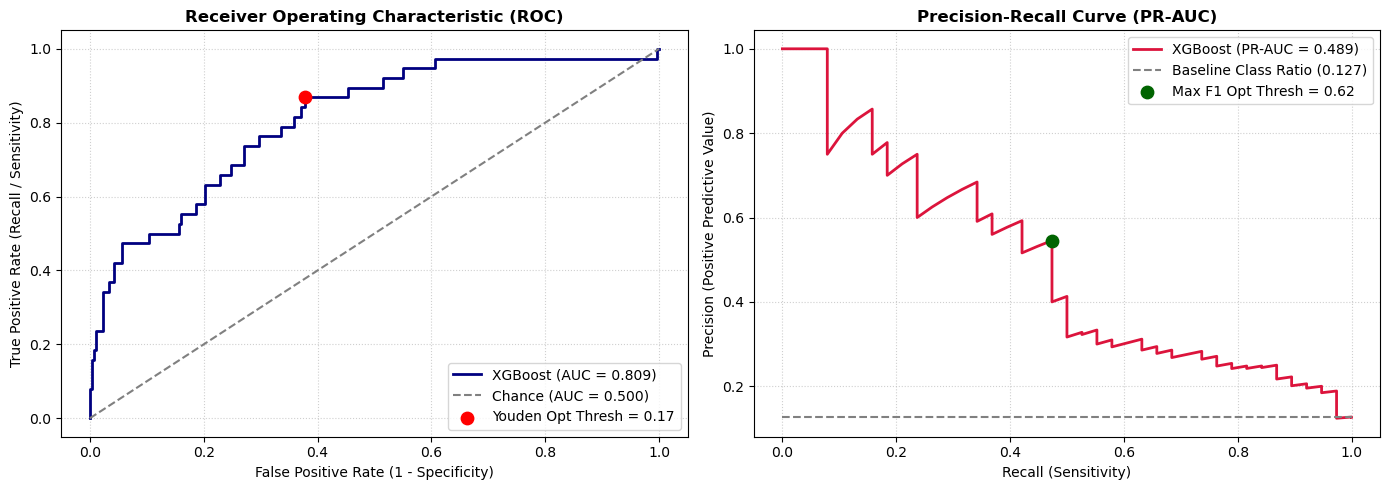

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, color='navy', lw=2, label=f'XGBoost (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Chance (AUC = 0.500)')
axes[0].scatter(fpr[best_youden_idx], tpr[best_youden_idx], color='red', s=80, zorder=5, 
               label=f'Youden Opt Thresh = {best_youden_thresh:.2f}')

axes[0].set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=10)
axes[0].set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right')

no_skill_baseline = sum(y_test) / len(y_test)
axes[1].plot(recall, precision, color='crimson', lw=2, label=f'XGBoost (PR-AUC = {pr_auc:.3f})')
axes[1].plot([0, 1], [no_skill_baseline, no_skill_baseline], color='gray', linestyle='--', 
              label=f'Baseline Class Ratio ({no_skill_baseline:.3f})')
axes[1].scatter(recall[:-1][best_f1_idx], precision[:-1][best_f1_idx], color='darkgreen', s=80, zorder=5, 
               label=f'Max F1 Opt Thresh = {best_f1_thresh:.2f}')

axes[1].set_title('Precision-Recall Curve (PR-AUC)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall (Sensitivity)', fontsize=10)
axes[1].set_ylabel('Precision (Positive Predictive Value)', fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import confusion_matrix, classification_report

In [28]:
def evaluate_threshold(y_true, y_probs, threshold, label_name):
    y_pred = (y_probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    
    print(f"\n================ Threshold Strategy: {label_name} (Cutoff = {threshold:.3f}) ================")
    print("Confusion Matrix:")
    print(pd.DataFrame(cm, index=['Actual No Event', 'Actual Event'], columns=['Pred No Event', 'Pred Event']))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=['No Event', 'Event'], zero_division=0))

evaluate_threshold(y_test, y_proba, 0.50, "Default 0.50 Probability Threshold")
evaluate_threshold(y_test, y_proba, best_youden_thresh, "Youden's J Index Threshold")
evaluate_threshold(y_test, y_proba, best_f1_thresh, "Maximal F1-Score Threshold")


================ Threshold Strategy: Default 0.50 Probability Threshold (Cutoff = 0.500) ================
Confusion Matrix:
                 Pred No Event  Pred Event
Actual No Event            231          31
Actual Event                19          19

Classification Report:
              precision    recall  f1-score   support

    No Event       0.92      0.88      0.90       262
       Event       0.38      0.50      0.43        38

    accuracy                           0.83       300
   macro avg       0.65      0.69      0.67       300
weighted avg       0.86      0.83      0.84       300


================ Threshold Strategy: Youden's J Index Threshold (Cutoff = 0.168) ================
Confusion Matrix:
                 Pred No Event  Pred Event
Actual No Event            163          99
Actual Event                 5          33

Classification Report:
              precision    recall  f1-score   support

    No Event       0.97      0.62      0.76       262
       Event    